In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "solid",
    "FLSQR-I": "solid",
    "FLSQR-R": "solid",
    "FLSQR-W": "solid",
    "IRW-FLSQR": "solid",
}


from trips.utilities.weights import smoothed_holder_weights


# from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
# from pgkbsolver import MMGKB, IASGKB, MM2019GKB
# from f2019solver import MM2019FGK2019, IASFGK2019


from msolver import VanillaGKS

# For reference, to match papers exactly:
# SGKS corresponds to msolver, MM2GKS ?
# SGKS (restarted) corresponds to msolver, MM1GKS
# SGKS (recycled) corresponds to msolver, MM2GKS ?
# PSGKS corresponds to msolver, MM2GKS
# PSGKB corresponds to pgkbsolver, MM2GKB
# FGK corresponds to fsolver, MM2FGK
# FLSQR-I corresponds to f2019solver, MM4FGK2019, with option I 
# FLSQR-R corresponds to f2019solver, MM4FGK2019, with option R
# FLSQR-W corresponds to f2019solver, MM4FGK2019, with option W <- we added this option ourselves, close to the method below
# IRW-FLSQR corresponds to fIRWsolver, MM2FGKIRW, with option IRW


from msolver import MM2GKS, MM1GKS, MMGKS
from pgkbsolver import MM2GKB
from fsolver import MM2FGK
from f2019solver import MM4FGK2019
from fIRWsolver import MM2FGKIRW


# Also the IAS imports
from msolver import IASGKS
from fsolver import IASFGK
from pgkbsolver import IASGKB
from f2019solver import IASFGK2019
from fIRWsolver import IASFGKIRW

# Setup the problem data

In [12]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)
ground_truth -= 5.5
ground_truth *= -1

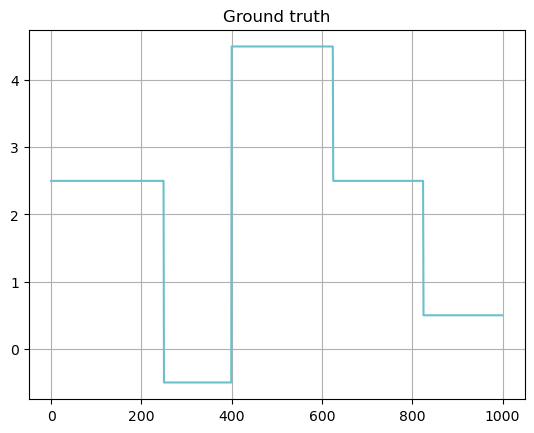

In [13]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [14]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


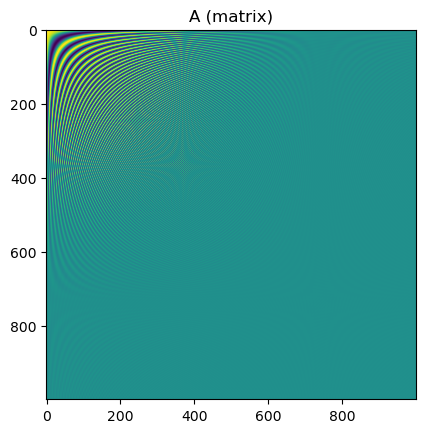

In [15]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [16]:
# Only first 50 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [17]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

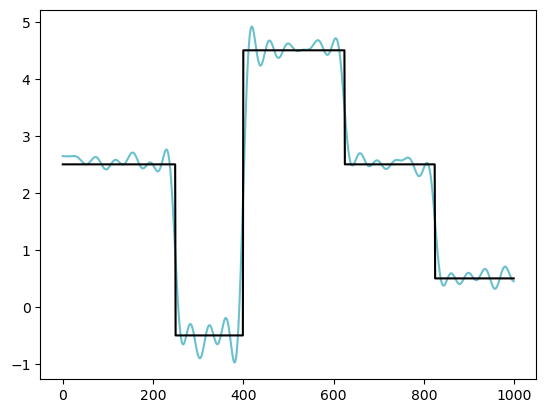

In [18]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [19]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))



# Run RMMGKS for different epsilon

In [20]:
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7


v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)


734.4247114348133
773.4913540627327
792.7646435688165
786.7947212547227
678.4096966018841
398.1030990218177
261.6985788419615
222.5772537620482
207.12262435777706
199.1489349912947
194.4712497396449
191.68058160550132
189.98769984019867
188.9407545638505
188.3192580745528
187.93155030095286
187.67406298505784
187.50640959098223
187.3773626339308
187.25679805816196
187.13438220593392
187.03423039306728
186.96873930334675
186.92695705730347
186.90215045553626
186.88283133917605
186.8678029119946
186.86570858542063
186.87507125576715
186.89381598965608
186.91736376635816
186.9370501948805
186.95321071633865
186.96858885412058
186.98339953185004
186.99530261963395
187.005226466949
187.0143463042034
187.02335563902187
187.03179454279942
187.0382934908616
187.0430259484341
187.0470223036739
187.05021945655372
187.0521144980719
187.05344174096933
187.0546805216003
187.05544264799784
187.05577245421875
187.05598119143846
187.0561220229203
187.05598952199165
187.05550868385896
187.0549666846016

In [21]:
epsilons = np.asarray([1.0, 0.1, 0.01, 0.001, 0.0001])

resdatas = []
recdatas = []

for epsilon in epsilons:

    mm_weight_params = {
        "q": 1.0,
        "epsilon": epsilon,
    }

    mm_gks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    # Recycled/restarted S-GKS
    mm_sgks_resdata = mm_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mm_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


    mm_sgks_recdata = mm_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)

    resdatas.append(mm_sgks_resdata)
    recdatas.append(mm_sgks_recdata)
        

Augmented basis with initial guess!


189.19526140816203
188.6878815443931
188.89716378922597
189.02460433573373
189.10856209722579
189.16682036252783
189.18644231208398
189.16350722360966
189.14497773115716
189.13555946268457
189.12353377138385
189.11188490502985
189.10495355904982
189.10193088912564
189.10191067239248
189.1042717194368
189.10633890939428
189.10623850242808
189.10663512848276
189.1079258777823
189.10847263891793
189.10747726058463
189.10700140666535
189.10761603216818
189.10786219075464
189.1080081123508
189.10795690253917
189.1076444810711
189.1076046192085
189.10767076658306
189.10760766302
189.10759257305597
189.10762530093797
189.10766186310846
189.10768178837222
189.1077046424922
189.10769998816048
189.10770605075638
189.10771794835352
189.10775279726727
189.1078872815532
189.1083067532641
189.10861797592565
189.108484097672
189.10840104621366
189.10838277512306
189.10834569437898
189.1084170846091
189.1085387226972
189.1084935334815
189.10841366616106
189.10845863115958
189.10846219230018
189.108661

189.19526140816203
188.6878815443931
188.89716378922597
189.02460433573373
189.10856209722579
189.16682036252783
189.18644231208398
189.16350722360966
189.14497773115716
189.13555946268457
189.12353377138385
189.11188490502985
189.10495355904982
189.10193088912564
189.10191067239248
189.1042717194368
189.10633890939428
189.10623850242808
189.10663512848276
189.1079258777823
189.10847263891793
189.10747726058463
189.10700140666535
189.10761603216818
189.10786219075464
189.1080081123508
189.10795690253917
189.1076444810711
189.1076046192085
189.10767076658306
189.10760766302
189.10759257305597
189.10762530093797
189.10766186310846
189.10768178837222
189.1077046424922
189.10769998816048
189.10770605075638
189.10771794835352
189.10775279726727
189.1078872815532
189.1083067532641
189.10861797592565
189.108484097672
189.10840104621366
189.10838277512306
189.10834569437898
189.1084170846091
189.1085387226972
189.1084935334815
189.10841366616106
189.10845863115958
189.10846219230018
189.108661

29.84842530116875
32.87143671658698
32.80174176141264
32.75155848112688
32.73682757017965
32.71671502511389
32.76817417893601
32.83806091172679
32.93484547925981
33.019860912840144
33.13256666465226
33.239155451800066
33.3215261482915
33.4021736297633
33.45927562628009
33.502459983481856
33.53473268467803
33.5579300990139
33.56622577584554
33.57111337180429
33.56423391989378
33.56540167131744
33.57164815380695
33.56469271111041
33.547567590302435
33.54362817204761
33.546654324705386
33.560500977140116
33.57795591318591
33.592202906611085
33.6065861795406
33.61584304027959
33.621124033076654
33.62378078769313
33.62410894777634
33.623420204372074
33.621453505105094
33.62003759861322
33.61895880553567
33.61881586595809
33.61927864754972
33.619159031725374
33.6182829873811
33.617527587025776
33.615681979954374
33.61304017239035
33.60855420062087
33.607501374500856
33.60622351300835
33.60350067803101
33.60333611216021
33.603487693094124
33.603497038073755
33.60339757422992
33.60348667409109

29.84842530116875
32.87143671658698
32.80174176141264
32.75155848112688
32.73682757017965
32.71671502511389
32.76817417893601
32.83806091172679
32.93484547925981
33.019860912840144
33.13256666465226
33.239155451800066
33.3215261482915
33.4021736297633
33.45927562628009
33.502459983481856
33.53473268467803
33.5579300990139
33.56622577584554
33.57111337180429
33.56423391989378
33.56540167131744
33.57164815380695
33.56469271111041
33.547567590302435
33.54362817204761
33.546654324705386
33.560500977140116
33.57795591318591
33.592202906611085
33.6065861795406
33.61584304027959
33.621124033076654
33.62378078769313
33.62410894777634
33.623420204372074
33.621453505105094
33.62003759861322
33.61895880553567
33.61881586595809
33.61927864754972
33.619159031725374
33.6182829873811
33.617527587025776
33.615681979954374
33.61304017239035
33.60855420062087
33.607501374500856
33.60622351300835
33.60350067803101
33.60333611216021
33.603487693094124
33.603497038073755
33.60339757422992
(50, 60)
(60, 60)

...

12.696301956274697
15.951099763000393
19.39341502434395
19.427636192633187
18.63641806468556
19.663814561807897
21.1891096082664
21.340262055871936
20.85972054359053
21.692381227329786
22.55674614897393
22.836217136681896
23.488141217470957
24.51614961047115
25.143953078342243
25.315202810249787
25.290325374551436
25.260377579326697
25.41245337276088
25.73474192888517
26.13404925032294
26.598106088522734
27.17149937446515
27.841528008757084
28.57932738343279
29.469509719682545
30.523666496059388
31.630597974287312
32.70848438025848
33.75795295932185
34.54350700387467
35.044514590921025
35.31941076290191
35.579505659808554
35.86071472806404
36.086992326934485
36.22784625171374
36.24324229475469
36.1389980399324
35.98819163012105
35.86162814443111
35.75163903090498
35.64370226364978
35.551510250762504
35.48966342281773
35.43994159532899
35.39874711473859
35.37084469832894
35.344647599788686
35.32030515707586
35.29303463634774
35.26800993926542
35.238672690597326
35.212826607551875
(50, 6

10.276081422571146
10.625451297097767
11.462383469730836
12.364877310031739
14.210770871906798
21.04899708731085
20.305901868361843
18.92765667088642
18.884121076054498
17.56032652626225
19.399592130087733
20.515643515173778
21.591794857585185
22.535300921508927
21.50422083856271
20.715397032478233
21.35079184867733
21.664674839807404
21.773782642298283
21.904484989782695
22.348277465778395
22.951444028513908
23.713445090267772
24.818513348701334
25.726471893514837
26.5755116609186
27.329646958141335
27.873477947856482
28.160142687264162
28.5113116366243
28.94167824807767
29.781265444077622
30.564192558750104
30.918368953519284
30.934745490269353
30.731638933779525
30.427242241719892
30.003085534363866
29.67657014428373
29.38110248558834
29.378701114886255
29.689961185123934
30.247817052418988
30.921970876746535
31.50778261613265
32.41368162791965
33.92662514134805
35.95162976956273
38.13814477953009
40.873357133081726
43.666236353863454
46.007003932361734
48.27725296998587
50.37732364

10.276081422571146
10.625451297097767
11.462383469730836
12.364877310031739
14.210770871906798
21.04899708731085
20.305901868361843
18.92765667088642
18.884121076054498
17.56032652626225
19.399592130087733
20.515643515173778
21.591794857585185
22.535300921508927
21.50422083856271
20.715397032478233
21.35079184867733
21.664674839807404
21.773782642298283
21.904484989782695
22.348277465778395
22.951444028513908
23.713445090267772
24.818513348701334
25.726471893514837
26.5755116609186
27.329646958141335
27.873477947856482
28.160142687264162
28.5113116366243
28.94167824807767
29.781265444077622
30.564192558750104
30.918368953519284
30.934745490269353
30.731638933779525
30.427242241719892
30.003085534363866
29.67657014428373
29.38110248558834
29.378701114886255
29.689961185123934
30.247817052418988
30.921970876746535
31.50778261613265
32.41368162791965
33.92662514134805
35.95162976956273
38.13814477953009
40.873357133081726
43.666236353863454
46.007003932361734
48.27725296998587
50.37732364

10.287453844177028
10.334963448510845
10.691727010210016
11.613249067826633
11.933600786858813
13.306162116900476
14.321760868247468
15.847250984619517
17.117393144469197
19.528619213923914
19.750676251683135
19.127379398395803
19.86447843860076
20.47416175440389
21.057108880305805
20.783719271228335
19.178098679451985
18.85861264530476
19.951576803622945
20.01423732835593
20.462986423933085
21.028704802202892
21.475642469246132
22.562645807160944
23.399069352823624
23.43245054185642
23.139194974924102
22.925243097745646
23.660996840242266
24.99780878534937
26.06504009348663
26.99070578193946
27.233159529666615
26.12201024060444
25.07175758648079
24.034561989873602
23.722583155565605
23.921876023704538
24.569625758073208
25.31918311735732
25.827651596281008
26.555082856925704
27.469732570715767
28.155607554915733
28.479120719628384
28.70089795885108
28.846946669916623
28.974748016402575
29.39142604869963
29.86897943825431
30.421865413528412
31.166203610460645
31.957091168891402
32.7503

10.287453844177028
10.334963448510845
10.691727010210016
11.613249067826633
11.933600786858813
13.306162116900476
14.321760868247468
15.847250984619517
17.117393144469197
19.528619213923914
19.750676251683135
19.127379398395803
19.86447843860076
20.47416175440389
21.057108880305805
20.783719271228335
19.178098679451985
18.85861264530476
19.951576803622945
20.01423732835593
20.462986423933085
21.028704802202892
21.475642469246132
22.562645807160944
23.399069352823624
23.43245054185642
23.139194974924102
22.925243097745646
23.660996840242266
24.99780878534937
26.06504009348663
26.99070578193946
27.233159529666615
26.12201024060444
25.07175758648079
24.034561989873602
23.722583155565605
23.921876023704538
24.569625758073208
25.31918311735732
25.827651596281008
26.555082856925704
27.469732570715767
28.155607554915733
28.479120719628384
28.70089795885108
28.846946669916623
28.974748016402575
29.39142604869963
29.86897943825431
30.421865413528412
31.166203610460645
31.957091168891402
32.7503

# Plotting

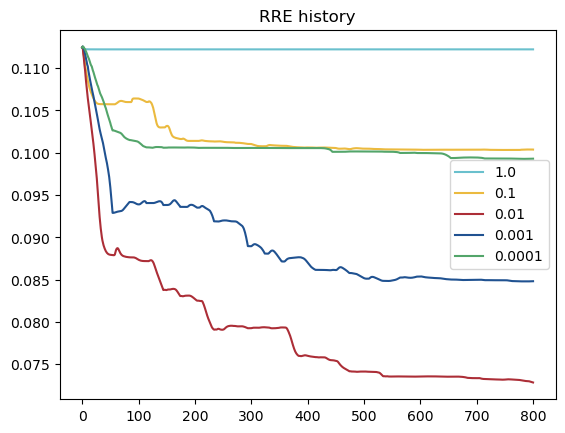

In [27]:
for j, epsilon in enumerate(epsilons):

    plt.plot(recdatas[j]["rre_history"], label=str(epsilon))

plt.title("RRE history")
plt.legend()

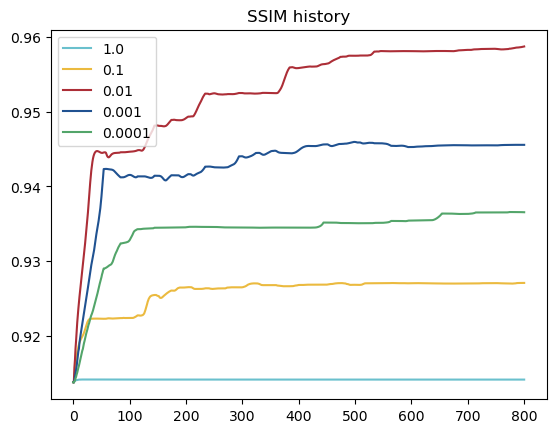

In [29]:
for j, epsilon in enumerate(epsilons):

    plt.plot(recdatas[j]["ssim_history"], label=str(epsilon))

plt.title("SSIM history")
plt.legend()

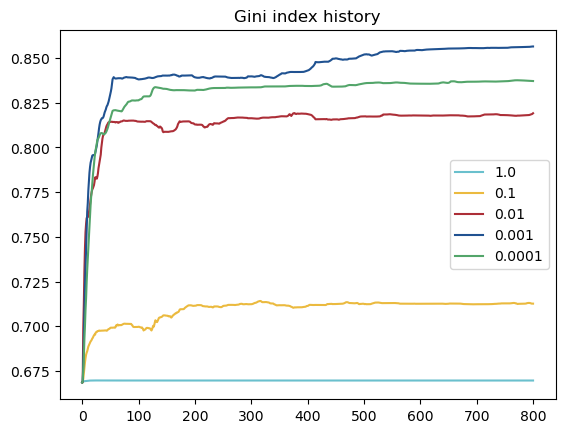

In [31]:
for j, epsilon in enumerate(epsilons):

    plt.plot(recdatas[j]["gini_indices"], label=str(epsilon))

plt.title("Gini index history")
plt.legend()

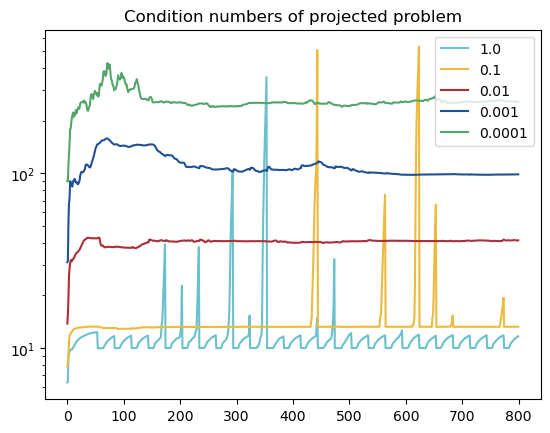

In [38]:
for j, epsilon in enumerate(epsilons):

    plt.semilogy(recdatas[j]["cond_ests"], label=str(epsilon))

plt.title("Condition numbers of projected problem")
plt.legend()
plt.show()

### Restarted?

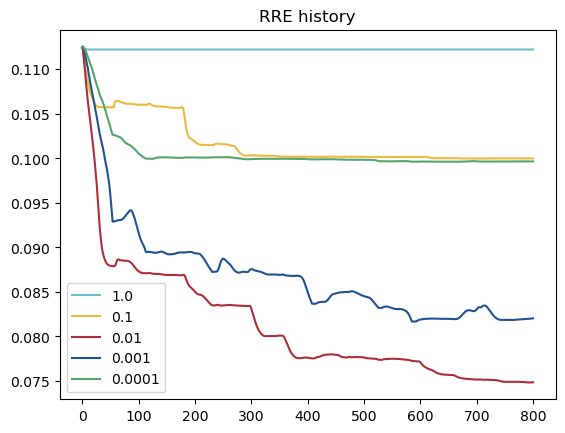

In [32]:
for j, epsilon in enumerate(epsilons):

    plt.plot(resdatas[j]["rre_history"], label=str(epsilon))

plt.title("RRE history")
plt.legend()

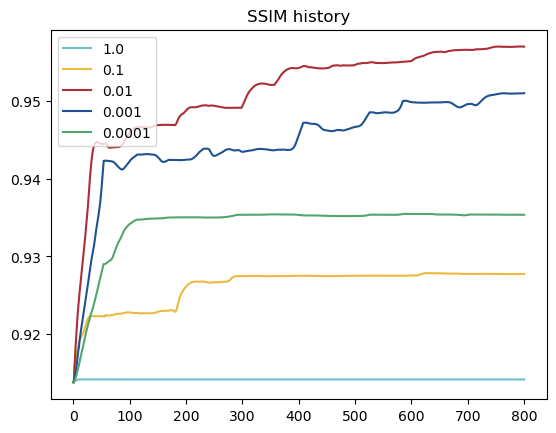

In [33]:
for j, epsilon in enumerate(epsilons):

    plt.plot(resdatas[j]["ssim_history"], label=str(epsilon))

plt.title("SSIM history")
plt.legend()

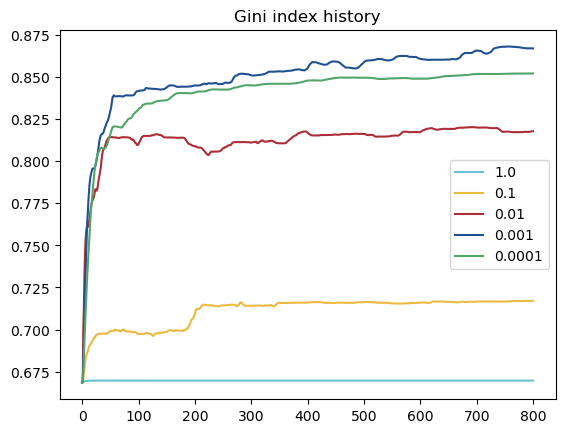

In [36]:
for j, epsilon in enumerate(epsilons):

    plt.plot(resdatas[j]["gini_indices"], label=str(epsilon))

plt.title("Gini index history")
plt.legend()
plt.show(

)

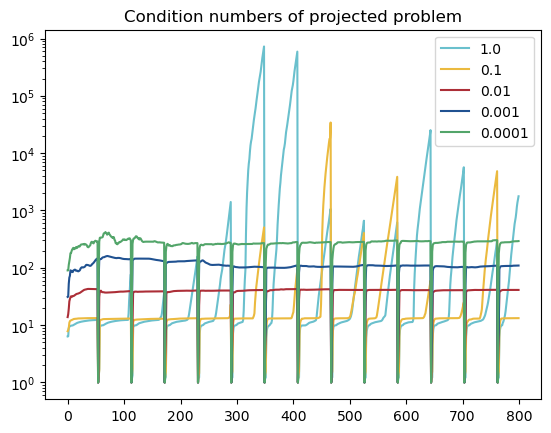

In [37]:
for j, epsilon in enumerate(epsilons):

    plt.semilogy(resdatas[j]["cond_ests"], label=str(epsilon))

plt.title("Condition numbers of projected problem")
plt.legend()
plt.show()